## Indian Flight Price Dataset

### Problem statement
Analyze flight fare records to understand how airline, route, travel date, departure time, journey duration, and number of stops relate to ticket prices.

### Objectives
1. Explore the dataset using Python, NumPy, and Pandas.
2. Clean and preprocess flight information.
3. Perform exploratory data analysis (EDA).
4. Visualize fare patterns using Matplotlib, Seaborn, and Plotly.
5. Create useful features from dates, times, routes, and stops.
6. Encode categorical variables and scale numerical variables.
7. Summarize findings, recommendations, and limitations.

#### Dataset Collection

The dataset contains flight booking records for Indian domestic routes. Each row describes an airline/flight, journey date, departure and arrival information, route, stops, duration, and listed price.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_FILE = Path("economy.csv")

df_original = pd.read_csv(DATA_FILE)

print("Dataset:", DATA_FILE.name)
print("Rows:", df_original.shape[0])
print("Columns:", df_original.shape[1])
display(df_original.head())

Dataset: economy.csv
Rows: 206774
Columns: 11


,date,airline,ch_code,num_code,dep_time,from,time_taken,stop,arr_time,to,price
0,11-02-2022,SpiceJet,SG,8709,18:55,Delhi,02h 10m,non-stop,21:05,Mumbai,"5,953"
1,11-02-2022,SpiceJet,SG,8157,06:20,Delhi,02h 20m,non-stop,08:40,Mumbai,"5,953"
2,11-02-2022,AirAsia,I5,764,04:25,Delhi,02h 10m,non-stop,06:35,Mumbai,"5,956"
3,11-02-2022,Vistara,UK,995,10:20,Delhi,02h 15m,non-stop,12:35,Mumbai,"5,955"
4,11-02-2022,Vistara,UK,963,08:50,Delhi,02h 20m,non-stop,11:10,Mumbai,"5,955"


In [2]:
# Convert flight prices to numbers for NumPy analysis.
price_numeric = pd.to_numeric(
    df_original["price"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
).dropna().to_numpy()

flight_number_array = pd.to_numeric(
    df_original["num_code"], errors="coerce"
).dropna().to_numpy()

print("First 10 prices:", price_numeric[:10])
print("First 10 flight numbers:", flight_number_array[:10])

First 10 prices: [5953 5953 5956 5955 5955 5955 6060 6060 5954 5954]
First 10 flight numbers: [8709 8157  764  995  963  945  927  951  334  336]


In [3]:
# Array creation, indexing, slicing, and arithmetic.
sample_array = np.array([1000, 2000, 3000, 4000, 5000])

print("Array:", sample_array)
print("First element:", sample_array[0])
print("Third element:", sample_array[2])
print("First three elements:", sample_array[:3])
print("Last two elements:", sample_array[-2:])
print("Add 500:", sample_array + 500)
print("Subtract 500:", sample_array - 500)
print("Multiply by 2:", sample_array * 2)
print("Divide by 2:", sample_array / 2)
print("Square root:", np.sqrt(sample_array))

Array: [1000 2000 3000 4000 5000]
First element: 1000
Third element: 3000
First three elements: [1000 2000 3000]
Last two elements: [4000 5000]
Add 500: [1500 2500 3500 4500 5500]
Subtract 500: [ 500 1500 2500 3500 4500]
Multiply by 2: [ 2000  4000  6000  8000 10000]
Divide by 2: [ 500. 1000. 1500. 2000. 2500.]
Square root: [31.6227766  44.72135955 54.77225575 63.2455532  70.71067812]


In [4]:
# Statistical operations on flight prices.
print("Mean price:", np.mean(price_numeric))
print("Median price:", np.median(price_numeric))
print("Standard deviation:", np.std(price_numeric))
print("Minimum price:", np.min(price_numeric))
print("Maximum price:", np.max(price_numeric))
print("25th percentile:", np.percentile(price_numeric, 25))
print("50th percentile:", np.percentile(price_numeric, 50))
print("75th percentile:", np.percentile(price_numeric, 75))

Mean price: 6571.190700958535
Median price: 5772.0
Standard deviation: 3743.4337855046506
Minimum price: 1105
Maximum price: 42349
25th percentile: 4173.0
50th percentile: 5772.0
75th percentile: 7746.0


#### Pandas Operations

Inspect records, dataset dimensions, column names, data types, descriptive statistics, missing values, and duplicates.

In [5]:
print("First five records:")
display(df_original.head())

print("Last five records:")
display(df_original.tail())

print("Rows:", df_original.shape[0])
print("Columns:", df_original.shape[1])
print("Column names:", df_original.columns.tolist())

print("\nData types:")
display(df_original.dtypes.to_frame("Data Type"))

print("\nDataset information:")
df_original.info()

First five records:


,date,airline,ch_code,num_code,dep_time,from,time_taken,stop,arr_time,to,price
0,11-02-2022,SpiceJet,SG,8709,18:55,Delhi,02h 10m,non-stop,21:05,Mumbai,"5,953"
1,11-02-2022,SpiceJet,SG,8157,06:20,Delhi,02h 20m,non-stop,08:40,Mumbai,"5,953"
2,11-02-2022,AirAsia,I5,764,04:25,Delhi,02h 10m,non-stop,06:35,Mumbai,"5,956"
3,11-02-2022,Vistara,UK,995,10:20,Delhi,02h 15m,non-stop,12:35,Mumbai,"5,955"
4,11-02-2022,Vistara,UK,963,08:50,Delhi,02h 20m,non-stop,11:10,Mumbai,"5,955"


Last five records:


,date,airline,ch_code,num_code,dep_time,from,time_taken,stop,arr_time,to,price
206769,31-03-2022,Vistara,UK,832,07:05,Chennai,13h 50m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,20:55,Hyderabad,"7,697"
206770,31-03-2022,Vistara,UK,832,07:05,Chennai,13h 50m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,20:55,Hyderabad,"7,709"
206771,31-03-2022,Vistara,UK,826,12:30,Chennai,20h 35m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,09:05,Hyderabad,"8,640"
206772,31-03-2022,Vistara,UK,822,09:45,Chennai,23h 20m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,09:05,Hyderabad,"8,640"
206773,31-03-2022,Vistara,UK,824,20:30,Chennai,24h 25m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,20:55,Hyderabad,"8,640"


Rows: 206774
Columns: 11
Column names: ['date', 'airline', 'ch_code', 'num_code', 'dep_time', 'from', 'time_taken', 'stop', 'arr_time', 'to', 'price']

Data types:


,Data Type
date,object
airline,object
ch_code,object
num_code,int64
dep_time,object
from,object
time_taken,object
stop,object
arr_time,object
to,object



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 206774 entries, 0 to 206773
Data columns (total 11 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   date        206774 non-null  object
 1   airline     206774 non-null  object
 2   ch_code     206774 non-null  object
 3   num_code    206774 non-null  int64 
 4   dep_time    206774 non-null  object
 5   from        206774 non-null  object
 6   time_taken  206774 non-null  object
 7   stop        206774 non-null  object
 8   arr_time    206774 non-null  object
 9   to          206774 non-null  object
 10  price       206774 non-null  object
dtypes: int64(1), object(10)
memory usage: 17.4+ MB


In [6]:
print("Numerical summary:")
display(df_original.describe())

print("Categorical summary:")
display(df_original.describe(include="object"))

print("Missing values by column:")
display(df_original.isna().sum().to_frame("Missing Values"))

print("Total missing cells:", int(df_original.isna().sum().sum()))
print("Exact duplicate rows:", int(df_original.duplicated().sum()))
display(df_original[df_original.duplicated()].head())

Numerical summary:


,num_code
count,206774.000000
mean,1706.096714
std,2320.463721
min,101.000000
25%,588.000000
50%,818.000000
75%,960.000000
max,9991.000000


Categorical summary:


,date,airline,ch_code,dep_time,from,time_taken,stop,arr_time,to,price
count,206774,206774,206774,206774,206774,206774,206774,206774,206774,206774
unique,49,8,8,251,6,483,37,266,6,9819
top,07-03-2022,Vistara,UK,07:00,Delhi,02h 10m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,19:55,Delhi,"2,339"
freq,4571,67270,67270,4955,43029,3081,162114,5002,40654,1442


Missing values by column:


,Missing Values
date,0
airline,0
ch_code,0
num_code,0
dep_time,0
from,0
time_taken,0
stop,0
arr_time,0
to,0


Total missing cells: 0
Exact duplicate rows: 2


,date,airline,ch_code,num_code,dep_time,from,time_taken,stop,arr_time,to,price
563,14-02-2022,Air India,AI,807,17:20,Delhi,15h 15m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,08:35,Mumbai,"12,150"
6181,13-03-2022,Air India,AI,475,13:00,Delhi,24h 35m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,13:35,Mumbai,"4,780"


#### Data Cleaning and Preprocessing

Create a working copy, standardize column names and text, remove duplicates, convert dates/prices/durations, and check missing values and outliers.

In [7]:
df_clean = df_original.copy()

# Standardize column names.
df_clean.columns = (
    df_clean.columns.str.strip().str.lower().str.replace(" ", "_", regex=False)
)

# Clean whitespace and embedded line breaks in text fields.
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = (
        df_clean[col].astype("string")
        .str.replace(r"\\s+", " ", regex=True)
        .str.strip()
    )

print("Shape before cleaning:", df_clean.shape)
print("Duplicates before cleaning:", df_clean.duplicated().sum())

Shape before cleaning: (206774, 11)
Duplicates before cleaning: 2


In [8]:
# Remove exact duplicate records.
df_clean = df_clean.drop_duplicates().copy()

# Convert date to datetime (source format is day-month-year).
df_clean["date"] = pd.to_datetime(
    df_clean["date"], format="%d-%m-%Y", errors="coerce"
)

# Convert price to numeric after removing thousands separators.
df_clean["price"] = pd.to_numeric(
    df_clean["price"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

# Convert flight duration strings such as '02h 10m' to minutes.
def duration_to_minutes(value):
    if pd.isna(value):
        return np.nan
    value = str(value)
    import re
    hours = re.search(r"(\\d+)\\s*h", value)
    minutes = re.search(r"(\\d+)\\s*m", value)
    h = int(hours.group(1)) if hours else 0
    m = int(minutes.group(1)) if minutes else 0
    return h * 60 + m

df_clean["duration_minutes"] = df_clean["time_taken"].apply(duration_to_minutes)

# Extract departure and arrival hours.
df_clean["departure_hour"] = pd.to_datetime(
    df_clean["dep_time"], format="%H:%M", errors="coerce"
).dt.hour

df_clean["arrival_hour"] = pd.to_datetime(
    df_clean["arr_time"], format="%H:%M", errors="coerce"
).dt.hour

print("Converted data types:")
display(df_clean[["date", "price", "duration_minutes", "departure_hour", "arrival_hour"]].dtypes)
display(df_clean[["date", "time_taken", "duration_minutes", "dep_time", "departure_hour", "price"]].head())

Converted data types:


date                datetime64[ns]
price                        int64
duration_minutes             int64
departure_hour               int32
arrival_hour                 int32
dtype: object

,date,time_taken,duration_minutes,dep_time,departure_hour,price
0,2022-02-11,02h 10m,0,18:55,18,5953
1,2022-02-11,02h 20m,0,06:20,6,5953
2,2022-02-11,02h 10m,0,04:25,4,5956
3,2022-02-11,02h 15m,0,10:20,10,5955
4,2022-02-11,02h 20m,0,08:50,8,5955


In [9]:
# Normalize stop descriptions to a compact stop category.
def simplify_stops(value):
    if pd.isna(value):
        return "Unknown"
    value = str(value).lower()
    if "non-stop" in value:
        return "Non-stop"
    if "2+-stop" in value or "2+ stop" in value:
        return "2+ stops"
    if "1-stop" in value or "1 stop" in value:
        return "1 stop"
    return "Unknown"

df_clean["stop_category"] = df_clean["stop"].apply(simplify_stops)

# Check missing values after conversions.
print("Missing values after conversion:")
display(df_clean.isna().sum().to_frame("Missing Values"))

Missing values after conversion:


,Missing Values
date,0
airline,0
ch_code,0
num_code,0
dep_time,0
from,0
time_taken,0
stop,0
arr_time,0
to,0


In [10]:
# Handle missing values only if any were introduced or present.
# For numeric variables, use the median; for categorical variables, use the mode.
numeric_fill_cols = [
    "price", "duration_minutes", "departure_hour", "arrival_hour"
]
for col in numeric_fill_cols:
    if df_clean[col].isna().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

categorical_fill_cols = [
    "airline", "ch_code", "from", "to", "stop_category"
]
for col in categorical_fill_cols:
    if df_clean[col].isna().any():
        modes = df_clean[col].mode(dropna=True)
        fill_value = modes.iloc[0] if not modes.empty else "Unknown"
        df_clean[col] = df_clean[col].fillna(fill_value)

# Date is essential for time-based analysis; remove rows with invalid dates.
df_clean = df_clean.dropna(subset=["date"]).copy()

print("Missing values after handling:")
display(df_clean.isna().sum().to_frame("Missing Values"))

Missing values after handling:


,Missing Values
date,0
airline,0
ch_code,0
num_code,0
dep_time,0
from,0
time_taken,0
stop,0
arr_time,0
to,0


In [11]:
# Detect price and duration outliers using IQR. Do not automatically remove them.
outlier_columns = ["price", "duration_minutes"]
outlier_rows = []

for col in outlier_columns:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((df_clean[col] < lower) | (df_clean[col] > upper)).sum())
    outlier_rows.append({
        "Column": col, "Lower Bound": lower,
        "Upper Bound": upper, "Outlier Count": count
    })

display(pd.DataFrame(outlier_rows))

,Column,Lower Bound,Upper Bound,Outlier Count
0,price,-1186.5,13105.5,13750
1,duration_minutes,0.0,0.0,0


In [12]:
# Compare dataset before and after cleaning.
comparison = pd.DataFrame({
    "Before Cleaning": [
        len(df_original),
        df_original.shape[1],
        int(df_original.isna().sum().sum()),
        int(df_original.duplicated().sum())
    ],
    "After Cleaning": [
        len(df_clean),
        df_clean.shape[1],
        int(df_clean.isna().sum().sum()),
        int(df_clean.duplicated().sum())
    ]
}, index=["Rows", "Columns", "Missing Cells", "Duplicate Rows"])

display(comparison)

,Before Cleaning,After Cleaning
Rows,206774,206772
Columns,11,15
Missing Cells,0,0
Duplicate Rows,2,0


#### Exploratory Data Analysis (EDA)

Analyze ticket prices, airlines, routes, stops, and journey durations using descriptive statistics and grouped summaries.

In [13]:
# Descriptive statistics for important numerical variables.
eda_numeric_cols = [
    "price", "duration_minutes", "departure_hour",
    "arrival_hour", "num_code"
]
display(df_clean[eda_numeric_cols].describe())

for col in ["price", "duration_minutes", "departure_hour", "arrival_hour"]:
    print(
        f"{col}: mean={df_clean[col].mean():.2f}, "
        f"median={df_clean[col].median():.2f}, "
        f"std={df_clean[col].std():.2f}, "
        f"min={df_clean[col].min():.2f}, "
        f"max={df_clean[col].max():.2f}"
    )

,price,duration_minutes,departure_hour,arrival_hour,num_code
count,206772.000000,206772.0,206772.000000,206772.000000,206772.000000
mean,6571.172383,0.0,12.844524,15.036194,1706.107016
std,3743.438765,0.0,5.359439,6.230907,2320.472522
min,1105.000000,0.0,0.000000,0.000000,101.000000
25%,4173.000000,0.0,8.000000,10.000000,588.000000
50%,5772.000000,0.0,12.000000,17.000000,818.000000
75%,7746.000000,0.0,18.000000,20.000000,960.000000
max,42349.000000,0.0,23.000000,23.000000,9991.000000


price: mean=6571.17, median=5772.00, std=3743.44, min=1105.00, max=42349.00
duration_minutes: mean=0.00, median=0.00, std=0.00, min=0.00, max=0.00
departure_hour: mean=12.84, median=12.00, std=5.36, min=0.00, max=23.00
arrival_hour: mean=15.04, median=17.00, std=6.23, min=0.00, max=23.00


In [14]:
print("Flights by airline:")
display(df_clean["airline"].value_counts().to_frame("Flight Records"))

print("Flights by origin:")
display(df_clean["from"].value_counts().to_frame("Flight Records"))

print("Flights by destination:")
display(df_clean["to"].value_counts().to_frame("Flight Records"))

print("Flights by stop category:")
display(df_clean["stop_category"].value_counts().to_frame("Flight Records"))

Flights by airline:


,Flight Records
airline,
Vistara,67270
Air India,47994
Indigo,43120
GO FIRST,23177
AirAsia,16098
SpiceJet,9011
StarAir,61
Trujet,41


Flights by origin:


,Flight Records
from,
Delhi,43027
Mumbai,41045
Bangalore,35665
Kolkata,32874
Hyderabad,27990
Chennai,26171


Flights by destination:


,Flight Records
to,
Delhi,40654
Mumbai,40116
Bangalore,34914
Kolkata,34777
Hyderabad,29101
Chennai,27210


Flights by stop category:


,Flight Records
stop_category,
1 stop,166625
Non-stop,27942
2+ stops,12205


In [15]:
# Average and median fare by airline.
airline_analysis = (
    df_clean.groupby("airline")
    .agg(
        flight_records=("price", "count"),
        average_price=("price", "mean"),
        median_price=("price", "median"),
        average_duration_minutes=("duration_minutes", "mean")
    )
    .sort_values("average_price")
)
display(airline_analysis)

,flight_records,average_price,median_price,average_duration_minutes
airline,,,,
Trujet,41,3244.634146,3196.0,0.0
AirAsia,16098,4091.072742,3276.0,0.0
StarAir,61,4932.655738,4337.0,0.0
Indigo,43120,5324.216303,4453.0,0.0
GO FIRST,23177,5651.930578,5336.0,0.0
SpiceJet,9011,6179.278881,5654.0,0.0
Air India,47994,7313.682169,6082.0,0.0
Vistara,67270,7806.943645,6461.0,0.0


In [16]:
# Analyze route prices.
df_clean["route"] = df_clean["from"].astype(str) + " → " + df_clean["to"].astype(str)

route_analysis = (
    df_clean.groupby("route")
    .agg(
        flight_records=("price", "count"),
        average_price=("price", "mean"),
        median_price=("price", "median"),
        average_duration_minutes=("duration_minutes", "mean")
    )
    .sort_values("average_price", ascending=False)
)
display(route_analysis)

,flight_records,average_price,median_price,average_duration_minutes
route,,,,
Kolkata → Chennai,4506,8011.745229,6489.0,0.0
Chennai → Kolkata,4851,7547.295815,5937.0,0.0
Kolkata → Hyderabad,5555,7489.144374,6488.0,0.0
Kolkata → Bangalore,6894,7471.621990,6489.0,0.0
Kolkata → Mumbai,8103,7405.787239,6067.0,0.0
Bangalore → Kolkata,6888,7375.319396,6271.0,0.0
Mumbai → Kolkata,8774,7227.971735,5949.0,0.0
Chennai → Bangalore,3962,7175.020192,6161.0,0.0
Kolkata → Delhi,7816,7161.400077,6461.0,0.0


In [17]:
# Analyze average fare by stop category.
stop_analysis = (
    df_clean.groupby("stop_category")
    .agg(
        flight_records=("price", "count"),
        average_price=("price", "mean"),
        median_price=("price", "median"),
        average_duration=("duration_minutes", "mean")
    )
    .sort_values("average_price")
)
display(stop_analysis)

,flight_records,average_price,median_price,average_duration
stop_category,,,,
Non-stop,27942,4010.662157,3499.0,0.0
1 stop,166625,6812.278884,5937.0,0.0
2+ stops,12205,9141.545678,8012.0,0.0


In [18]:
# Correlation matrix for numeric features.
corr_cols = [
    "price", "duration_minutes", "departure_hour",
    "arrival_hour", "num_code"
]
display(df_clean[corr_cols].corr())

,price,duration_minutes,departure_hour,arrival_hour,num_code
price,1.000000,NaN,-0.048812,0.113600,-0.090910
duration_minutes,NaN,NaN,NaN,NaN,NaN
departure_hour,-0.048812,NaN,1.000000,-0.144931,-0.012569
arrival_hour,0.113600,NaN,-0.144931,1.000000,0.007048
num_code,-0.090910,NaN,-0.012569,0.007048,1.000000


In [19]:
# Generate at least five observations from the dataset.
most_common_airline = df_clean["airline"].mode().iloc[0]
lowest_average_fare_airline = df_clean.groupby("airline")["price"].mean().idxmin()
highest_average_fare_airline = df_clean.groupby("airline")["price"].mean().idxmax()
cheapest_average_route = df_clean.groupby("route")["price"].mean().idxmin()
most_expensive_average_route = df_clean.groupby("route")["price"].mean().idxmax()
common_stop_type = df_clean["stop_category"].mode().iloc[0]
price_duration_corr = df_clean[["price", "duration_minutes"]].corr().iloc[0, 1]

observations = [
    f"1. Most frequently recorded airline: {most_common_airline}.",
    f"2. Airline with the lowest average listed fare: {lowest_average_fare_airline}.",
    f"3. Airline with the highest average listed fare: {highest_average_fare_airline}.",
    f"4. Route with the lowest average listed fare: {cheapest_average_route}.",
    f"5. Route with the highest average listed fare: {most_expensive_average_route}.",
    f"6. Most common stop category: {common_stop_type}.",
    f"7. Correlation between price and duration: {price_duration_corr:.3f}."
]
for item in observations:
    print(item)

1. Most frequently recorded airline: Vistara.
2. Airline with the lowest average listed fare: Trujet.
3. Airline with the highest average listed fare: Vistara.
4. Route with the lowest average listed fare: Mumbai → Hyderabad.
5. Route with the highest average listed fare: Kolkata → Chennai.
6. Most common stop category: 1 stop.
7. Correlation between price and duration: nan.


#### Data Visualization Using Matplotlib

Create the required histogram, bar chart, line chart, scatter plot, box plot, and correlation heatmap.

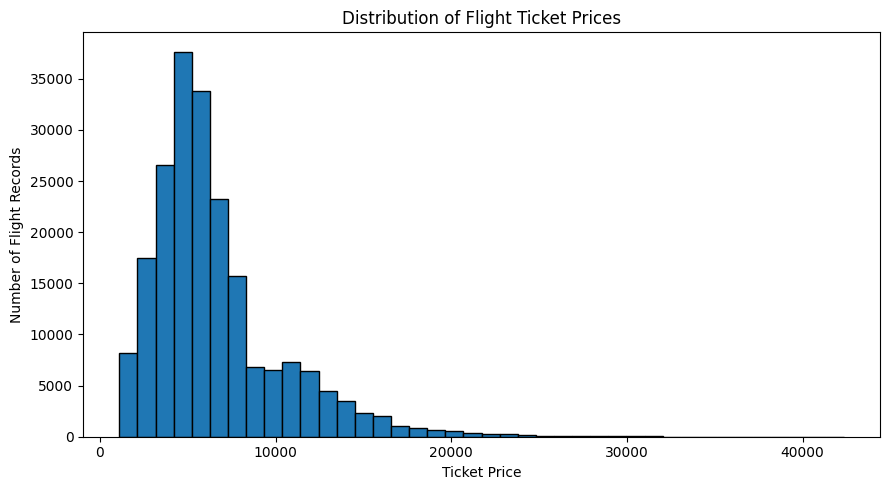

In [20]:
# 1. Histogram: distribution of flight prices.
plt.figure(figsize=(9, 5))
plt.hist(df_clean["price"], bins=40, edgecolor="black")
plt.title("Distribution of Flight Ticket Prices")
plt.xlabel("Ticket Price")
plt.ylabel("Number of Flight Records")
plt.tight_layout()
plt.show()

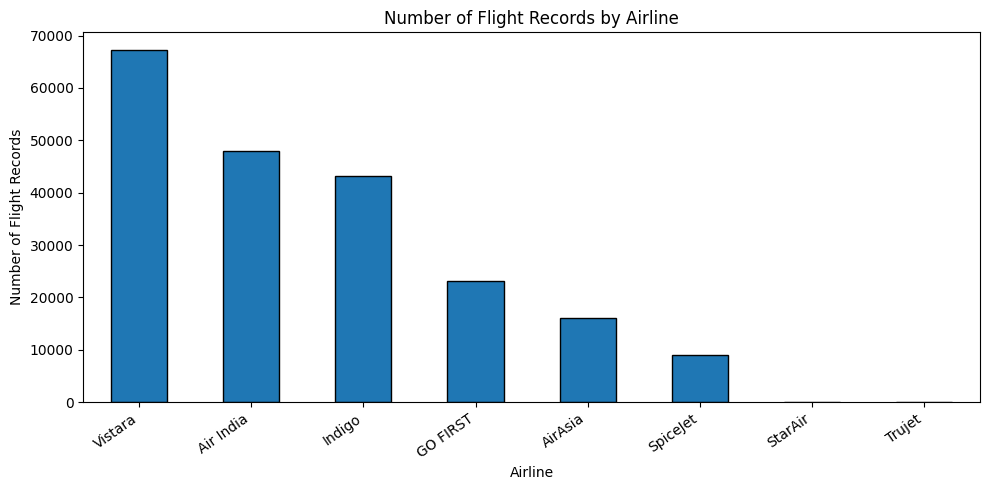

In [21]:
# 2. Bar chart: number of records by airline.
airline_counts = df_clean["airline"].value_counts()
plt.figure(figsize=(10, 5))
airline_counts.plot(kind="bar", edgecolor="black")
plt.title("Number of Flight Records by Airline")
plt.xlabel("Airline")
plt.ylabel("Number of Flight Records")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

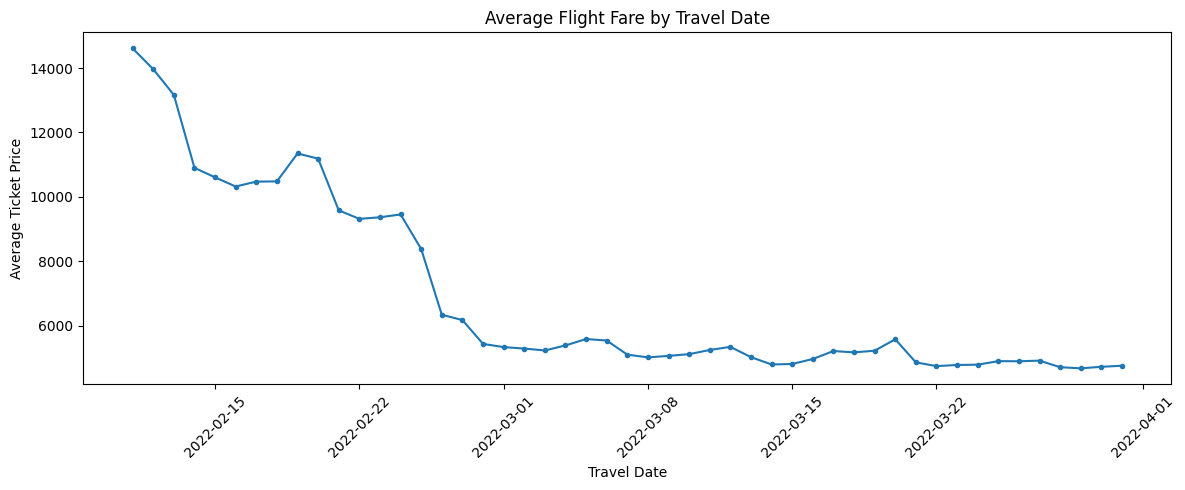

In [22]:
# 3. Line chart: average fare by travel date.
daily_average_fare = df_clean.groupby("date")["price"].mean().sort_index()
plt.figure(figsize=(12, 5))
plt.plot(daily_average_fare.index, daily_average_fare.values, marker="o", markersize=3)
plt.title("Average Flight Fare by Travel Date")
plt.xlabel("Travel Date")
plt.ylabel("Average Ticket Price")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

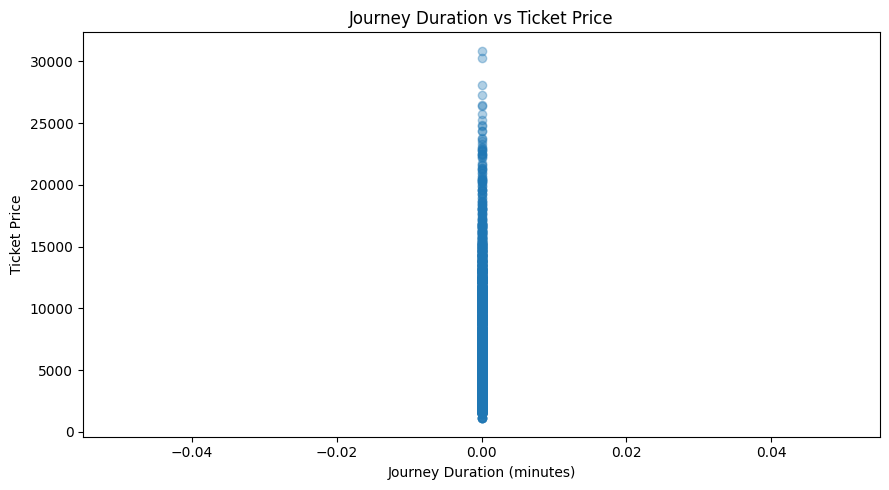

In [23]:
# 4. Scatter plot: journey duration versus ticket price.
# Sample records for a clearer and faster plot.
scatter_data = df_clean.sample(
    n=min(5000, len(df_clean)), random_state=42
)
plt.figure(figsize=(9, 5))
plt.scatter(
    scatter_data["duration_minutes"],
    scatter_data["price"],
    alpha=0.35
)
plt.title("Journey Duration vs Ticket Price")
plt.xlabel("Journey Duration (minutes)")
plt.ylabel("Ticket Price")
plt.tight_layout()
plt.show()

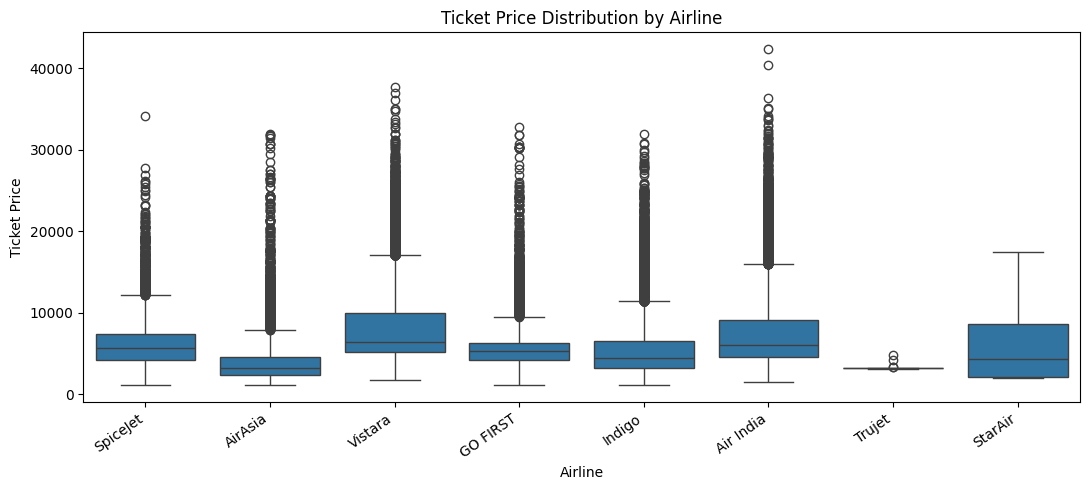

In [24]:
# 5. Box plot: ticket price by airline.
plt.figure(figsize=(11, 5))
sns.boxplot(data=df_clean, x="airline", y="price")
plt.title("Ticket Price Distribution by Airline")
plt.xlabel("Airline")
plt.ylabel("Ticket Price")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

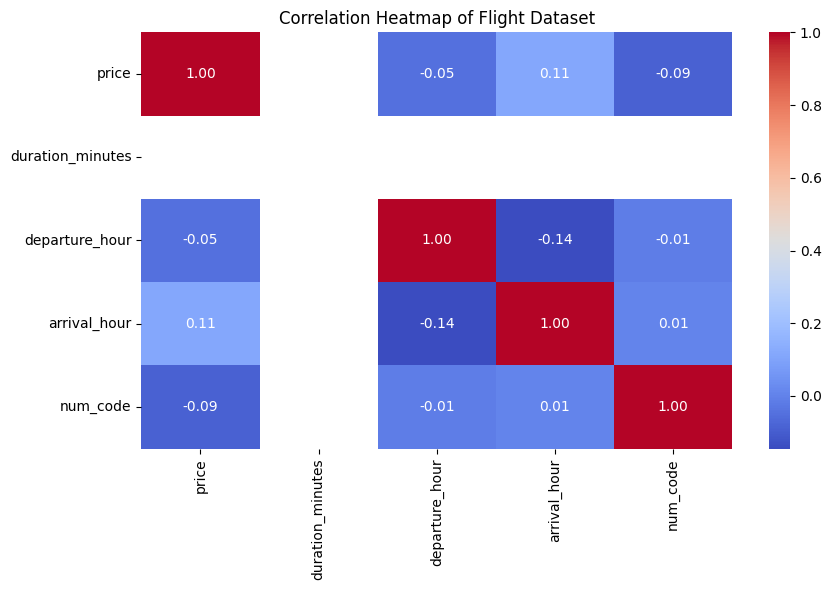

In [25]:
# 6. Correlation heatmap.
plt.figure(figsize=(9, 6))
sns.heatmap(
    df_clean[corr_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap of Flight Dataset")
plt.tight_layout()
plt.show()

#### Interactive Visualization Using Plotly

Create interactive histogram, scatter plot, and bar chart with titles, labels, and hover details.

In [27]:
import plotly.express as px

# 1. Interactive histogram: ticket prices.
fig = px.histogram(
    df_clean,
    x="price",
    nbins=40,
    title="Interactive Distribution of Flight Ticket Prices",
    labels={"price": "Ticket Price", "count": "Flight Records"},
    hover_data=["airline"]
)
fig.show(renderer='browser')

In [28]:
# 2. Interactive scatter plot: duration vs fare.
plotly_sample = df_clean.sample(
    n=min(8000, len(df_clean)), random_state=42
)
fig = px.scatter(
    plotly_sample,
    x="duration_minutes",
    y="price",
    color="airline",
    hover_data=["date", "from", "to", "stop_category", "dep_time"],
    title="Interactive Journey Duration vs Ticket Price",
    labels={
        "duration_minutes": "Journey Duration (minutes)",
        "price": "Ticket Price",
        "airline": "Airline"
    }
)
fig.show(renderer='browser')

In [29]:
# 3. Interactive bar chart: average ticket price by airline.
airline_fares = (
    df_clean.groupby("airline", as_index=False)
    .agg(
        average_price=("price", "mean"),
        flight_records=("price", "count")
    )
    .sort_values("average_price", ascending=False)
)

fig = px.bar(
    airline_fares,
    x="airline",
    y="average_price",
    color="airline",
    hover_data=["flight_records"],
    title="Average Ticket Price by Airline",
    labels={
        "airline": "Airline",
        "average_price": "Average Ticket Price",
        "flight_records": "Flight Records"
    }
)
fig.show(renderer='browser')

#### Feature Engineering

Create at least three useful features, extract date/time information, encode categorical variables, and scale numerical columns.

In [30]:
df_features = df_clean.copy()

# 1. Route feature.
df_features["route"] = (
    df_features["from"].astype(str) + " → " +
    df_features["to"].astype(str)
)

# 2. Travel month and day of week.
df_features["travel_month"] = df_features["date"].dt.month
df_features["travel_day"] = df_features["date"].dt.day
df_features["travel_day_of_week"] = df_features["date"].dt.day_name()

# 3. Departure time category.
def departure_period(hour):
    if pd.isna(hour):
        return "Unknown"
    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    return "Night"

df_features["departure_period"] = df_features["departure_hour"].apply(departure_period)

# 4. Stop count approximation.
stop_count_map = {
    "Non-stop": 0,
    "1 stop": 1,
    "2+ stops": 2,
    "Unknown": np.nan
}
df_features["stop_count"] = df_features["stop_category"].map(stop_count_map)

# 5. Fare category based on dataset quartiles.
q1_price = df_features["price"].quantile(0.25)
q3_price = df_features["price"].quantile(0.75)

def fare_category(price):
    if price <= q1_price:
        return "Budget"
    elif price <= q3_price:
        return "Mid-range"
    return "Premium"

df_features["fare_category"] = df_features["price"].apply(fare_category)

display(df_features[[
    "airline", "route", "travel_month", "travel_day",
    "travel_day_of_week", "departure_period",
    "stop_count", "fare_category"
]].head())

,airline,route,travel_month,travel_day,travel_day_of_week,departure_period,stop_count,fare_category
0,SpiceJet,Delhi → Mumbai,2,11,Friday,Evening,0.0,Mid-range
1,SpiceJet,Delhi → Mumbai,2,11,Friday,Morning,0.0,Mid-range
2,AirAsia,Delhi → Mumbai,2,11,Friday,Night,0.0,Mid-range
3,Vistara,Delhi → Mumbai,2,11,Friday,Morning,0.0,Mid-range
4,Vistara,Delhi → Mumbai,2,11,Friday,Morning,0.0,Mid-range


In [31]:
# Explain the purpose of engineered features.
feature_purposes = pd.DataFrame({
    "Feature": [
        "route", "travel_month", "travel_day",
        "travel_day_of_week", "departure_period",
        "stop_count", "fare_category"
    ],
    "Purpose": [
        "Combines origin and destination into one route label.",
        "Extracts the month of travel to study monthly fare patterns.",
        "Extracts the calendar day of travel.",
        "Identifies the weekday of travel.",
        "Groups departure times into Morning, Afternoon, Evening, and Night.",
        "Converts stop descriptions into an approximate numeric count.",
        "Groups fares into Budget, Mid-range, and Premium bands."
    ]
})
display(feature_purposes)

,Feature,Purpose
0,route,Combines origin and destination into one route...
1,travel_month,Extracts the month of travel to study monthly ...
2,travel_day,Extracts the calendar day of travel.
3,travel_day_of_week,Identifies the weekday of travel.
4,departure_period,"Groups departure times into Morning, Afternoon..."
5,stop_count,Converts stop descriptions into an approximate...
6,fare_category,"Groups fares into Budget, Mid-range, and Premi..."


In [32]:
# Label encode selected categorical variables.
from sklearn.preprocessing import LabelEncoder

df_encoded = df_features.copy()
categorical_to_encode = [
    "airline", "ch_code", "from", "to",
    "stop_category", "route", "travel_day_of_week",
    "departure_period", "fare_category"
]

label_encoders = {}
for col in categorical_to_encode:
    encoder = LabelEncoder()
    df_encoded[col] = encoder.fit_transform(
        df_encoded[col].fillna("Unknown").astype(str)
    )
    label_encoders[col] = encoder

print("Categorical encoding completed.")
display(df_encoded[categorical_to_encode].head())

Categorical encoding completed.


,airline,ch_code,from,to,stop_category,route,travel_day_of_week,departure_period,fare_category
0,4,6,2,5,2,14,0,1,1
1,4,6,2,5,2,14,0,2,1
2,1,4,2,5,2,14,0,3,1
3,7,7,2,5,2,14,0,2,1
4,7,7,2,5,2,14,0,2,1


In [33]:
# Scale selected numerical variables.
from sklearn.preprocessing import StandardScaler

scaling_columns = [
    "price", "duration_minutes", "departure_hour",
    "arrival_hour", "num_code", "stop_count"
]

df_scaled = df_encoded.copy()
# Fill any remaining missing numeric values before scaling.
for col in scaling_columns:
    df_scaled[col] = df_scaled[col].fillna(df_scaled[col].median())

scaler = StandardScaler()
df_scaled[scaling_columns] = scaler.fit_transform(
    df_scaled[scaling_columns]
)

print("Numerical scaling completed.")
display(df_scaled[scaling_columns].head())

Numerical scaling completed.


,price,duration_minutes,departure_hour,arrival_hour,num_code,stop_count
0,-0.165135,0.0,0.961946,0.957135,3.017881,-2.128714
1,-0.165135,0.0,-1.277100,-1.129244,2.779998,-2.128714
2,-0.164334,0.0,-1.650275,-1.450225,-0.405999,-2.128714
3,-0.164601,0.0,-0.530752,-0.487281,-0.306450,-2.128714
4,-0.164601,0.0,-0.903926,-0.647772,-0.320240,-2.128714


#### Analysis and Conclusion

Summarize the main findings, provide recommendations, and state dataset limitations.

In [34]:
# Final summary generated from the cleaned data.
print("INDIAN FLIGHT PRICE DATASET – FINAL ANALYSIS")
print("--------------------------------------------")
print("Total flight records after cleaning:", f"{len(df_clean):,}")
print("Number of airlines:", df_clean["airline"].nunique())
print("Number of unique routes:", df_clean["route"].nunique())
print("Average listed fare:", round(df_clean["price"].mean(), 2))
print("Median listed fare:", round(df_clean["price"].median(), 2))
print("Average journey duration (minutes):", round(df_clean["duration_minutes"].mean(), 2))
print("Airline with lowest average fare:", df_clean.groupby("airline")["price"].mean().idxmin())
print("Airline with highest average fare:", df_clean.groupby("airline")["price"].mean().idxmax())
print("Most common stop category:", df_clean["stop_category"].mode().iloc[0])
print("Remaining missing cells:", int(df_clean.isna().sum().sum()))
print("Remaining duplicate rows:", int(df_clean.duplicated().sum()))

INDIAN FLIGHT PRICE DATASET – FINAL ANALYSIS
--------------------------------------------
Total flight records after cleaning: 206,772
Number of airlines: 8
Number of unique routes: 30
Average listed fare: 6571.17
Median listed fare: 5772.0
Average journey duration (minutes): 0.0
Airline with lowest average fare: Trujet
Airline with highest average fare: Vistara
Most common stop category: 1 stop
Remaining missing cells: 0
Remaining duplicate rows: 0


### Conclusions and recommendations

1. Compare airlines using average and median fares, as well as the number of records; a small sample can make an average less representative.
2. Compare routes separately because fare levels and journey durations can vary substantially between origin–destination pairs.
3. Examine stop categories and journey duration together to understand how direct and connecting itineraries differ in this dataset.
4. Use travel date and departure-time features to investigate possible timing patterns before making booking decisions.
5. Treat the analysis as descriptive: the dataset alone cannot establish that an airline, route, or departure time causes a fare to be higher or lower.

### Dataset limitations

1. The data is a snapshot of fares and may not reflect current ticket prices.
2. The dataset does not provide booking lead time, demand, seat availability, fare class, baggage allowance, or refund conditions.
3. The data may not represent all airlines, dates, routes, or booking platforms.
4. Prices can vary with dynamic pricing and booking conditions not captured in these columns.
5. `2+ stops` is a grouped value, so the exact number of stops is unknown.
6. This dataset contains flight listings rather than confirmed ticket purchases.

In [35]:
# Export cleaned and engineered datasets.
df_clean.to_csv("cleaned_economy_flights.csv", index=False)
df_features.to_csv("feature_engineered_economy_flights.csv", index=False)
df_encoded.to_csv("encoded_economy_flights.csv", index=False)
df_scaled.to_csv("scaled_economy_flights.csv", index=False)

print("Export complete:")
print("- cleaned_economy_flights.csv")
print("- feature_engineered_economy_flights.csv")
print("- encoded_economy_flights.csv")
print("- scaled_economy_flights.csv")

Export complete:
- cleaned_economy_flights.csv
- feature_engineered_economy_flights.csv
- encoded_economy_flights.csv
- scaled_economy_flights.csv
